<!-- # Copyright (c) 2026 takotime808 -->
# Hypervolume and Hypervolume Regret

`multioutreg.metrics` scores multi-objective surrogates through the **hypervolume** a Pareto
front dominates. This notebook shows what `hypervolume` and `hypervolume_regret` compute,
step by step, and checks each step against an independent calculation:

1. [Pareto fronts and hypervolume](#hv): `pareto_mask` and `hypervolume` in 2-D
2. [The regret](#regret): `hypervolume_regret(Y_true, Y_pred)` on a small example
3. [The reference point](#ref): the default, and why to fix it when comparing models
4. [Maximization and mixed objectives](#minimize): the `minimize` argument
5. [Front fidelity versus decision regret](#decision): two questions, two ways to call it
6. [A surrogate on ZDT1](#zdt1): regret against training-set size, with `RegretTracker`
7. [Beyond two objectives](#nd): exact hypervolume in 3 to 6 dimensions, and a 3-objective
   surrogate on DTLZ2
8. [Summary](#summary)

Everything is minimization unless stated otherwise: smaller objective values are better.

In [1]:
import time
import warnings
from itertools import combinations

warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import qmc

from multioutreg.active.benchmarks import get_benchmark, zdt_front
from multioutreg.metrics import RegretTracker, hypervolume, hypervolume_regret, pareto_mask
from multioutreg.surrogates import GaussianProcessSurrogate

BLUE, ORANGE, GREEN, PINK, GREY = "#0072B2", "#E69F00", "#009E73", "#CC79A7", "0.6"


def front_of(Y):
    # Non-dominated rows of Y, sorted by the first objective.
    F = Y[pareto_mask(Y)]
    return F[np.argsort(F[:, 0])]


def shade_dominated(ax, F, ref, color, label, alpha=0.25):
    # Shade the region a 2-D front dominates up to the reference point (minimization).
    F = front_of(F)
    xs = np.r_[F[:, 0], ref[0]]
    ys = np.r_[F[:, 1], F[-1, 1]]
    ax.fill_between(xs, ys, ref[1], step="post", color=color, alpha=alpha, lw=0, label=label)
    ax.step(xs, ys, where="post", color=color, lw=1.5)

<a id="hv"></a>
## 1. Pareto fronts and hypervolume

A point **dominates** another if it is no worse in every objective and better in at least
one. The **Pareto front** is the set of points nothing dominates; `pareto_mask(Y)` returns a
boolean mask of them.

The **hypervolume** of a front is the area (in 2-D; volume in higher dimensions) between the
front and a **reference point** that is worse than every point. Larger is better: a front
closer to the origin, or one that covers more of the trade-off, dominates more.
`hypervolume(Y, reference_point)` returns it, ignoring dominated rows.

Below, six points with two objectives. Four are on the front; the hypervolume is the shaded
staircase. With the reference point at (5, 5) it is a sum of rectangles, worked out by hand.

on the front: [ True  True  True  True False False]
hypervolume by hand:   10.5
hypervolume(Y, ref):   10.5


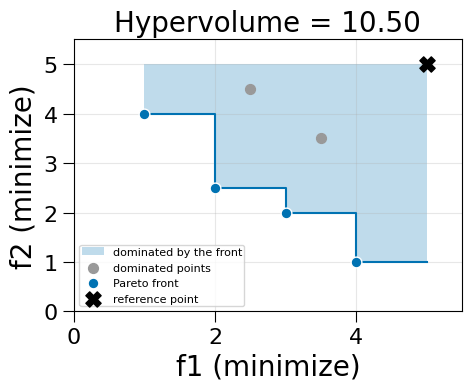

In [2]:
Y = np.array([[1.0, 4.0], [2.0, 2.5], [3.0, 2.0], [4.0, 1.0], [3.5, 3.5], [2.5, 4.5]])
ref = np.array([5.0, 5.0])
mask = pareto_mask(Y)
print("on the front:", mask)

# By hand: sort the front by f1 and add one rectangle per point,
# width (ref_x - x) and height (previous y - y).
by_hand, prev_y = 0.0, ref[1]
for x, y in front_of(Y):
    by_hand += (ref[0] - x) * (prev_y - y)
    prev_y = y
print(f"hypervolume by hand:   {by_hand}")
print(f"hypervolume(Y, ref):   {hypervolume(Y, reference_point=ref)}")

fig, ax = plt.subplots(figsize=(5, 4.2))
shade_dominated(ax, Y, ref, BLUE, "dominated by the front")
ax.scatter(*Y[~mask].T, s=50, color=GREY, zorder=3, label="dominated points")
ax.scatter(*Y[mask].T, s=60, color=BLUE, edgecolor="white", zorder=4, label="Pareto front")
ax.scatter(*ref, marker="X", s=120, color="black", zorder=4, label="reference point")
ax.set(xlabel="f1 (minimize)", ylabel="f2 (minimize)", xlim=(0, 5.5), ylim=(0, 5.5),
       title=f"Hypervolume = {by_hand:.2f}")
ax.legend(fontsize=8, loc="lower left")
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

<a id="regret"></a>
## 2. The regret

`hypervolume_regret(Y_true, Y_pred, reference_point=None, minimize=True)`:

1. finds the Pareto front of `Y_true` and of `Y_pred` separately;
2. computes the hypervolume of each against the same reference point;
3. returns $\max\big(0,\ \mathrm{HV}(\text{front}(Y_\text{true})) - \mathrm{HV}(\text{front}(Y_\text{pred}))\big)$.

Below, a "prediction" of the same six designs with every objective 0.4 too high
(pessimistic): its front sits further from the origin and dominates less, and the regret is
the blue area the orange front does not reach.

hypervolume(Y_true) = 10.500
hypervolume(Y_pred) = 7.460
hypervolume_regret  = 3.040  (= the difference)


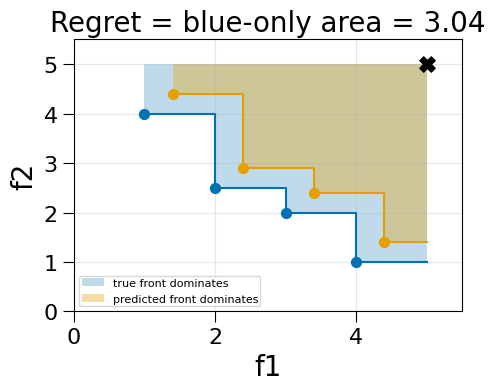

In [3]:
Y_true = Y
Y_pess = Y + 0.4
regret = hypervolume_regret(Y_true, Y_pess, reference_point=ref)
print(f"hypervolume(Y_true) = {hypervolume(Y_true, ref):.3f}")
print(f"hypervolume(Y_pred) = {hypervolume(Y_pess, ref):.3f}")
print(f"hypervolume_regret  = {regret:.3f}  (= the difference)")

fig, ax = plt.subplots(figsize=(5, 4.2))
shade_dominated(ax, Y_true, ref, BLUE, "true front dominates")
shade_dominated(ax, Y_pess, ref, ORANGE, "predicted front dominates", alpha=0.35)
ax.scatter(*front_of(Y_true).T, s=50, color=BLUE, zorder=4)
ax.scatter(*front_of(Y_pess).T, s=50, color=ORANGE, zorder=4)
ax.scatter(*ref, marker="X", s=120, color="black", zorder=4)
ax.set(xlabel="f1", ylabel="f2", xlim=(0, 5.5), ylim=(0, 5.5),
       title=f"Regret = blue-only area = {regret:.2f}")
ax.legend(fontsize=8, loc="lower left")
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

<a id="ref"></a>
## 3. The reference point

Hypervolume depends on the reference point, and so does the regret. If `reference_point` is
not given, `hypervolume_regret` uses a point 10% of the range beyond the worst value of each
objective, taken over **both** `Y_true` and `Y_pred` together (1.0 beyond it if an objective is
constant).

Because the default depends on `Y_pred`, two models scored with the default reference get
**different** reference points, and their regrets are not on the same scale. Fix the reference
point from the true values (or from known objective bounds) whenever models are compared.

In [4]:
models = {"pessimistic by 0.4": Y_true + 0.4, "pessimistic by 1.5": Y_true + 1.5}
fixed_ref = Y_true.max(0) + 0.1 * np.ptp(Y_true, 0) + 2.0   # worse than every prediction below

rows = []
for name, Yp in models.items():
    allY = np.vstack([Y_true, Yp])
    default_ref = allY.max(0) + 0.1 * np.ptp(allY, 0)        # what the function picks
    rows.append({
        "model": name,
        "default reference point": np.round(default_ref, 2),
        "regret (default reference)": hypervolume_regret(Y_true, Yp),
        f"regret (fixed reference {np.round(fixed_ref, 2)})": hypervolume_regret(Y_true, Yp, reference_point=fixed_ref),
    })
pd.DataFrame(rows).set_index("model").round(3)

,default reference point,regret (default reference),regret (fixed reference [6.3 6.85])
model,,,
pessimistic by 0.4,"[4.74, 5.29]",3.052,4.300
pessimistic by 1.5,"[5.95, 6.5]",13.425,14.475


The worse model's predictions push the default reference point further out, which inflates
both hypervolumes; the regrets are then measured on different scales. With one fixed
reference the comparison is fair. A reference point that is *not* worse than a point gives
that point zero contribution, so choose it beyond the worst value you expect.

<a id="minimize"></a>
## 4. Maximization and mixed objectives

`minimize` is either one boolean for all objectives or one per objective. Objectives with
`False` are maximized: internally their values are negated so that everything is minimized.
The reference point is used in that internal convention, so for a maximized objective pass
the **negated** reference coordinate: take the point that is worst in your own units (for a
maximized objective, a value *below* every point) and multiply its maximized coordinates by −1.

Below, the same data with $f_2$ redefined as $f_2' = -f_2$, to be maximized. In those units
the worst corner is $(f_1, f_2') = (5, -5)$; negating its second coordinate gives $(5, 5)$,
and the regret matches the all-minimized case.

In [5]:
flip = np.array([1.0, -1.0])
Y_true_mixed, Y_pess_mixed = Y_true * flip, Y_pess * flip   # f2' = -f2, larger is better
ref_user = np.array([5.0, -5.0])                            # worst corner in the user's units

print("all minimized, ref (5, 5):            ",
      round(hypervolume_regret(Y_true, Y_pess, reference_point=ref), 4))
print("f2' maximized, ref_user * flip:        ",
      round(hypervolume_regret(Y_true_mixed, Y_pess_mixed, reference_point=ref_user * flip,
                               minimize=[True, False]), 4))
print("f2' maximized, ref_user not negated:   ",
      round(hypervolume_regret(Y_true_mixed, Y_pess_mixed, reference_point=ref_user,
                               minimize=[True, False]), 4),
      " <- wrong: internally (5, -5) is better than every point in f2")

all minimized, ref (5, 5):             3.04
f2' maximized, ref_user * flip:         3.04
f2' maximized, ref_user not negated:    0.0  <- wrong: internally (5, -5) is better than every point in f2


<a id="decision"></a>
## 5. Front fidelity versus decision regret

`hypervolume_regret(Y_true, Y_pred)` compares the *predicted* front with the true front. That
answers "**how well does the surrogate predict where the front is?**"

An engineer using a surrogate for optimization usually needs a different answer: "**if I run
the designs the surrogate calls Pareto-optimal, how much worse off am I than if I had run the
truly best designs?**" That is **decision regret**: evaluate the *true* objectives at the
surrogate's picks. The same function computes it when the second argument is the true values at
the picks:

```python
picks = pareto_mask(Y_pred)
decision_regret = hypervolume_regret(Y_true, Y_true[picks], reference_point=ref)
```

Four "surrogates" of the six designs show how the two disagree:

- **exact**: the true values.
- **optimistic**: every objective predicted 0.8 too low. It ranks the designs exactly right.
- **pessimistic**: every objective 0.4 too high. Also ranks them right.
- **reshuffled**: predicts the right *set* of values but assigns them to the wrong designs, so
  its predicted front is perfect while its picks are wrong.

In [6]:
surrogates = {
    "exact": Y_true.copy(),
    "optimistic (all 0.8 too low)": Y_true - 0.8,
    "pessimistic (all 0.4 too high)": Y_true + 0.4,
    "reshuffled (right values, wrong designs)": Y_true[[5, 4, 3, 2, 1, 0]],
}
rows = []
for name, Yp in surrogates.items():
    picks = pareto_mask(Yp)
    rows.append({
        "surrogate": name,
        "designs picked": np.flatnonzero(picks).tolist(),
        "front fidelity: hypervolume_regret(Y_true, Y_pred)": hypervolume_regret(Y_true, Yp, reference_point=ref),
        "decision regret: hypervolume_regret(Y_true, Y_true[picks])": hypervolume_regret(Y_true, Y_true[picks], reference_point=ref),
    })
print("truly Pareto-optimal designs:", np.flatnonzero(pareto_mask(Y_true)).tolist())
pd.DataFrame(rows).set_index("surrogate").round(3)

truly Pareto-optimal designs: [0, 1, 2, 3]


,designs picked,"front fidelity: hypervolume_regret(Y_true, Y_pred)","decision regret: hypervolume_regret(Y_true, Y_true[picks])"
surrogate,,,
exact,"[0, 1, 2, 3]",0.00,0.00
optimistic (all 0.8 too low),"[0, 1, 2, 3]",0.00,0.00
pessimistic (all 0.4 too high),"[0, 1, 2, 3]",3.04,0.00
"reshuffled (right values, wrong designs)","[2, 3, 4, 5]",0.00,3.25


**Reading the table.**

- The **optimistic** surrogate picks the right designs (decision regret 0) and also scores 0
  on front fidelity, but for a different reason: its predicted front dominates *more* than the
  true one, and the difference is clipped at zero. Front fidelity therefore cannot tell an
  accurate model from an over-optimistic one.
- The **pessimistic** surrogate also picks the right designs (decision regret 0) but is
  charged on front fidelity, because its front is in the wrong place.
- The **reshuffled** surrogate has a perfect predicted front (front fidelity 0) while picking
  dominated designs, which only decision regret detects.

Use decision regret to judge a surrogate for optimization. Use front fidelity to judge how
well the front's location is predicted, and check for optimism by also computing it with the
arguments swapped, `hypervolume_regret(Y_pred, Y_true)`.

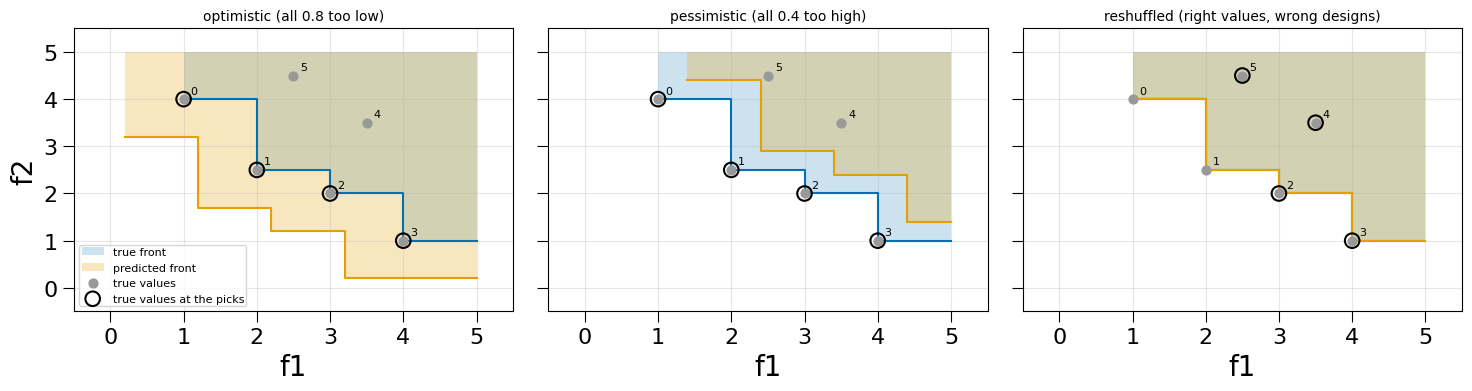

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), sharex=True, sharey=True)
for ax, name in zip(axes, ["optimistic (all 0.8 too low)", "pessimistic (all 0.4 too high)",
                           "reshuffled (right values, wrong designs)"]):
    Yp = surrogates[name]
    picks = pareto_mask(Yp)
    shade_dominated(ax, Y_true, ref, BLUE, "true front", alpha=0.2)
    shade_dominated(ax, Yp, ref, ORANGE, "predicted front", alpha=0.25)
    ax.scatter(*Y_true.T, s=40, color=GREY, zorder=3, label="true values")
    ax.scatter(*Y_true[picks].T, s=110, facecolor="none", edgecolor="black", lw=1.5, zorder=4,
               label="true values at the picks")
    for i, (x, y) in enumerate(Y_true):
        ax.annotate(str(i), (x, y), xytext=(5, 4), textcoords="offset points", fontsize=8)
    ax.set_title(name, fontsize=10)
    ax.set_xlabel("f1")
    ax.set(xlim=(-0.5, 5.5), ylim=(-0.5, 5.5))
    ax.grid(alpha=0.3)
axes[0].set_ylabel("f2")
axes[0].legend(fontsize=8, loc="lower left")
fig.tight_layout()
plt.show()

<a id="zdt1"></a>
## 6. A surrogate on ZDT1

ZDT1 (`get_benchmark("zdt1")`, 6 inputs, 2 objectives) has an exact Pareto front,
$f_2 = 1 - \sqrt{f_1}$, returned by `zdt_front("zdt1")`. A GP surrogate is trained on
increasing numbers of runs and used to screen 2,000 random candidate designs. Both regrets use
one fixed reference point.

`RegretTracker` records `hypervolume_regret` (front fidelity), scalarized regret and the
ε-indicator for each step of a loop; decision regret is tracked alongside by hand.

In [8]:
bench = get_benchmark("zdt1")
X_cand = bench.sample(2000, method="random", seed=7)
Y_cand = bench(X_cand)
ref_zdt = np.array([1.1, 1.1 * Y_cand[:, 1].max()])

sizes = [10, 20, 40, 80, 160]
tracker = RegretTracker(reference_point=ref_zdt)
decision, optimism, n_picked, t0 = [], [], [], time.time()
for n in sizes:
    X = bench.sample(n, method="lhs", seed=0)
    P = GaussianProcessSurrogate().fit(X, bench(X)).predict(X_cand)
    tracker.step(Y_cand, P)
    picks = pareto_mask(P)
    decision.append(hypervolume_regret(Y_cand, Y_cand[picks], reference_point=ref_zdt))
    optimism.append(hypervolume_regret(P, Y_cand, reference_point=ref_zdt))   # arguments swapped
    n_picked.append(int(picks.sum()))

history = pd.DataFrame({
    "training runs": sizes,
    "designs picked": n_picked,
    "decision regret": decision,
    "front fidelity (tracker 'hv')": tracker.history["hv"],
    "optimism check": optimism,
    "scalarized (tracker)": tracker.history["scalar"],
    "epsilon (tracker)": tracker.history["eps"],
}).set_index("training runs")
print(f"{time.time() - t0:.1f} s; hypervolume of the candidates' front: {hypervolume(Y_cand, ref_zdt):.3f}")
history.round(4)

5.4 s; hypervolume of the candidates' front: 7.673


,designs picked,decision regret,front fidelity (tracker 'hv'),optimism check,scalarized (tracker),epsilon (tracker)
training runs,,,,,,
10,13,0.0000,0.0000,0.1613,0.1520,0.0323
20,14,0.0000,0.0000,0.1018,0.0793,0.0000
40,13,0.0000,0.0083,0.0000,-0.0150,0.0553
80,14,0.0000,0.0417,0.0000,-0.0263,0.0981
160,12,0.0034,0.0450,0.0000,-0.0341,0.1175


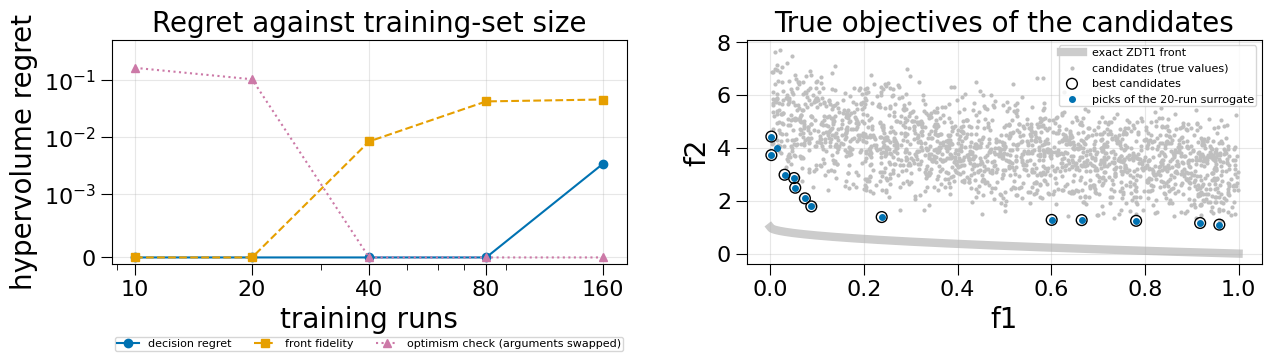

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
ax = axes[0]
ax.plot(sizes, history["decision regret"], "o-", color=BLUE, label="decision regret")
ax.plot(sizes, history["front fidelity (tracker 'hv')"], "s--", color=ORANGE, label="front fidelity")
ax.plot(sizes, history["optimism check"], "^:", color=PINK, label="optimism check (arguments swapped)")
ax.set(xscale="log", yscale="symlog", xlabel="training runs", ylabel="hypervolume regret",
       title="Regret against training-set size")
ax.set_yscale("symlog", linthresh=1e-3)
ax.set_ylim(-1e-4, 0.5)
ax.set_xticks(sizes, [str(s) for s in sizes])
ax.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.3), ncol=3)
ax.grid(alpha=0.3)

ax = axes[1]
X = bench.sample(20, method="lhs", seed=0)
picks20 = pareto_mask(GaussianProcessSurrogate().fit(X, bench(X)).predict(X_cand))
ax.plot(*zdt_front("zdt1").T, color="0.8", lw=6, zorder=1, label="exact ZDT1 front")
ax.scatter(*Y_cand.T, s=4, color="0.75", zorder=2, label="candidates (true values)")
ax.scatter(*Y_cand[pareto_mask(Y_cand)].T, s=60, facecolor="none", edgecolor="black", zorder=3,
           label="best candidates")
ax.scatter(*Y_cand[picks20].T, s=16, color=BLUE, zorder=4, label="picks of the 20-run surrogate")
ax.set(xlabel="f1", ylabel="f2", title="True objectives of the candidates")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

**Reading the result.** ZDT1 is easy to *rank*: $f_1 = x_1$ is learned exactly and $f_2$
grows with every other input, so even the 10-run surrogate picks the best candidates and
its decision regret is zero (it becomes slightly positive, 0.003, only at
160 runs). Front fidelity tells the opposite story: it is **zero for the small surrogates and
grows with more data**. The 10- and 20-run surrogates predict objectives that are too good
(the optimism check, with the arguments swapped, is positive), and the clipping turns that
into a perfect score; as the surrogate becomes accurate, the optimism disappears and its
remaining errors are charged. So front fidelity should never be read without the optimism
check.

The tracker's scalarized regret is signed (it is $\min w \cdot Y_\text{true} - \min w \cdot Y_\text{pred}$
averaged over weights), so it is positive for optimistic and negative for pessimistic
predictions. The candidates are random designs, which lie well above the exact front (right
panel), so all regrets are measured against the best of the candidates.

<a id="nd"></a>
## 7. Beyond two objectives

`hypervolume` and `hypervolume_regret` are exact for any number of objectives. In 1-D the
hypervolume is $\text{ref} - \min f$, and in 2-D it is the rectangle sum of section 1. For
$m \ge 3$ the front is **sliced** along the last objective: between two consecutive values
$z_k < z_{k+1}$ of it, the dominated region's cross-section is the $(m-1)$-objective
hypervolume of the points with $f_m \le z_k$, so

$$\mathrm{HV}_m = \sum_k \mathrm{HV}_{m-1}\big(\{f : f_m \le z_k\}\big)\,(z_{k+1} - z_k),$$

with $z_{n+1}$ the reference point's last coordinate, recursing down to the exact 2-D sweep.
When `pymoo` is installed (`pip install multioutreg[moo]`) its faster exact algorithm is used
for $m \ge 3$ instead; the values agree.

### 7a. Checking it

Two independent checks:

- **Inclusion–exclusion.** The dominated region is the union of the boxes $[f, \text{ref}]$,
  so its volume is $\sum_{S} (-1)^{|S|+1} \operatorname{vol}\big(\bigcap_{f \in S} [f, \text{ref}]\big)$
  over all non-empty subsets $S$ of the front. Exact, but $2^n$ terms, so only for small fronts.
- **A closed-form limit.** Points on the positive part of a sphere of radius $r$ (the shape of
  the DTLZ2 front) dominate, with reference point $(1, 1, 1)$, at most the unit cube minus the
  eighth-ball, $1 - \pi r^3 / 6$. As the front gets denser, its hypervolume must approach that
  value from below.

In [10]:
def hv_inclusion_exclusion(F, ref):
    # Exact volume of the union of boxes [f, ref]; 2^n terms, small fronts only.
    F = F[pareto_mask(F)]
    total = 0.0
    for k in range(1, len(F) + 1):
        for subset in combinations(range(len(F)), k):
            total += (-1) ** (k + 1) * np.prod(ref - F[list(subset)].max(axis=0))
    return total


rng = np.random.default_rng(0)
rows = []
for m in [3, 4, 5, 6]:
    F = rng.random((10, m))
    ref_m = np.full(m, 1.1)
    rows.append({"objectives": m, "points": len(F), "front size": int(pareto_mask(F).sum()),
                 "hypervolume()": hypervolume(F, ref_m),
                 "inclusion-exclusion": hv_inclusion_exclusion(F, ref_m)})
check = pd.DataFrame(rows).set_index("objectives")
check["abs. difference"] = (check["hypervolume()"] - check["inclusion-exclusion"]).abs()
check

,points,front size,hypervolume(),inclusion-exclusion,abs. difference
objectives,,,,,
3,10,8,0.721383,0.721383,5.551115e-16
4,10,7,0.674673,0.674673,4.440892e-16
5,10,9,0.125931,0.125931,5.551115e-17
6,10,9,0.178587,0.178587,1.665335e-16


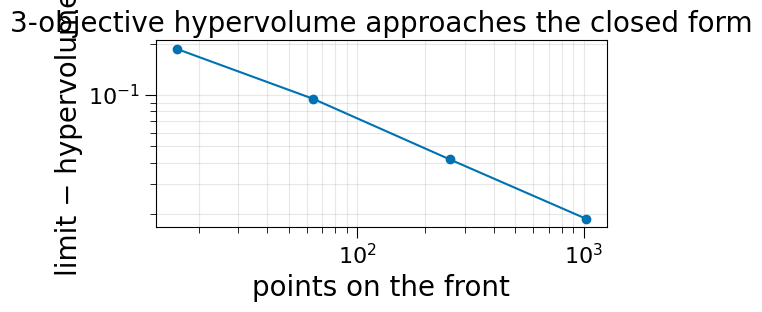

,hypervolume,limit 1 - πr³/6,gap to limit,seconds
front points,,,,
16,0.43198,0.6183,0.18631,0.00113
64,0.52334,0.6183,0.09496,0.00660
256,0.57633,0.6183,0.04197,0.07912
1024,0.59949,0.6183,0.01881,1.24396


In [11]:
def sphere_front(n, r, seed=0):
    # n points spread over the positive octant of a sphere of radius r.
    U = qmc.Sobol(2, scramble=True, seed=seed).random(n)
    theta, phi = U[:, 0] * np.pi / 2, U[:, 1] * np.pi / 2
    return r * np.column_stack([np.cos(theta) * np.cos(phi), np.cos(theta) * np.sin(phi), np.sin(theta)])


r, ref3 = 0.9, np.ones(3)
limit = 1 - np.pi * r ** 3 / 6
rows = []
for n in [16, 64, 256, 1024]:
    F = sphere_front(n, r)
    t = time.time()
    hv_n = hypervolume(F, ref3)
    rows.append({"front points": n, "hypervolume": hv_n, "limit 1 - πr³/6": limit,
                 "gap to limit": limit - hv_n, "seconds": time.time() - t})
conv = pd.DataFrame(rows).set_index("front points")

fig, ax = plt.subplots(figsize=(6, 3.4))
ax.plot(conv.index, conv["gap to limit"], "o-", color=BLUE)
ax.set(xscale="log", yscale="log", xlabel="points on the front", ylabel="limit − hypervolume",
       title="3-objective hypervolume approaches the closed form")
ax.grid(alpha=0.3, which="both")
fig.tight_layout()
plt.show()
conv.round(5)

The gap to the closed form shrinks steadily as the front gets denser and never goes negative:
a finite front can only dominate less than the continuous surface it samples.

### 7b. Run time

The slicing recursion costs roughly $n^{m-1}$ operations for a front of $n$ points. Below,
fronts where *every* point is non-dominated (the worst case), timed without `pymoo`.

In [12]:
from multioutreg.metrics.multiobjective_regret import _hv_exact_min  # the pure-NumPy path

rng = np.random.default_rng(1)
rows = []
for m, sizes in [(3, [50, 200, 500]), (4, [50, 100, 200]), (5, [30, 60]), (6, [20, 40])]:
    for n in sizes:
        V = np.abs(rng.normal(size=(n, m)))
        F = 0.9 * V / np.linalg.norm(V, axis=1, keepdims=True)   # all on the front
        t = time.time()
        _hv_exact_min(F, np.ones(m))
        rows.append({"objectives": m, "front size": n, "seconds": time.time() - t})
pd.DataFrame(rows).pivot(index="front size", columns="objectives", values="seconds").round(3)

objectives,3,4,5,6
front size,,,,
20,NaN,NaN,NaN,0.190
30,NaN,NaN,0.148,NaN
40,NaN,NaN,NaN,2.819
50,0.005,0.078,NaN,NaN
60,NaN,NaN,0.831,NaN
100,NaN,0.196,NaN,NaN
200,0.048,1.282,NaN,NaN
500,0.277,NaN,NaN,NaN


Three and four objectives with fronts of hundreds of points take well under two seconds.
For five or more objectives with large fronts, install `pymoo`, whose algorithm scales
better.

### 7c. A three-objective surrogate: DTLZ2

DTLZ2 (Deb et al. 2005) with 3 objectives and 7 inputs: the first two inputs place a point on
the sphere octant, the other five push it outwards through
$g = \sum_{i \ge 3} (x_i - 0.5)^2$, and the true front is the unit sphere ($g = 0$):

$$f_1 = (1 + g)\cos\tfrac{\pi x_1}{2}\cos\tfrac{\pi x_2}{2},\quad
f_2 = (1 + g)\cos\tfrac{\pi x_1}{2}\sin\tfrac{\pi x_2}{2},\quad
f_3 = (1 + g)\sin\tfrac{\pi x_1}{2}.$$

As on ZDT1, a GP screens 3,000 random candidates and decision regret is computed from the true
values at its picks, now with exact 3-D hypervolumes.

In [13]:
def dtlz2(X):
    # DTLZ2 with three objectives on [0, 1]^d (d >= 3).
    g = ((X[:, 2:] - 0.5) ** 2).sum(axis=1)
    a, b = np.pi / 2 * X[:, 0], np.pi / 2 * X[:, 1]
    return (1 + g)[:, None] * np.column_stack([np.cos(a) * np.cos(b), np.cos(a) * np.sin(b), np.sin(a)])


d = 7
X_cand3 = np.random.default_rng(11).random((3000, d))
Y_cand3 = dtlz2(X_cand3)
ref_d = np.full(3, 1.1 * Y_cand3.max())
best3 = pareto_mask(Y_cand3)

rows, t0 = [], time.time()
for n in [20, 40, 80, 160]:
    X = qmc.LatinHypercube(d, seed=0).random(n)
    P = GaussianProcessSurrogate().fit(X, dtlz2(X)).predict(X_cand3)
    picks = pareto_mask(P)
    rows.append({
        "training runs": n,
        "designs picked": int(picks.sum()),
        "best candidates among picks": f"{(picks & best3).sum()} of {best3.sum()}",
        "decision regret": hypervolume_regret(Y_cand3, Y_cand3[picks], reference_point=ref_d),
        "front fidelity": hypervolume_regret(Y_cand3, P, reference_point=ref_d),
        "optimism check: hypervolume_regret(P, Y_true)": hypervolume_regret(P, Y_cand3, reference_point=ref_d),
    })
print(f"{time.time() - t0:.1f} s; hypervolume of the candidates' front: {hypervolume(Y_cand3, ref_d):.4f}")
dtlz_table = pd.DataFrame(rows).set_index("training runs")
dtlz_table.round(4)

9.1 s; hypervolume of the candidates' front: 8.2071


,designs picked,best candidates among picks,decision regret,front fidelity,"optimism check: hypervolume_regret(P, Y_true)"
training runs,,,,,
20,297,34 of 160,0.2341,0.0,0.4527
40,327,99 of 160,0.0620,0.0,0.6970
80,224,127 of 160,0.0488,0.0,1.1229
160,149,124 of 160,0.0255,0.0,0.8260


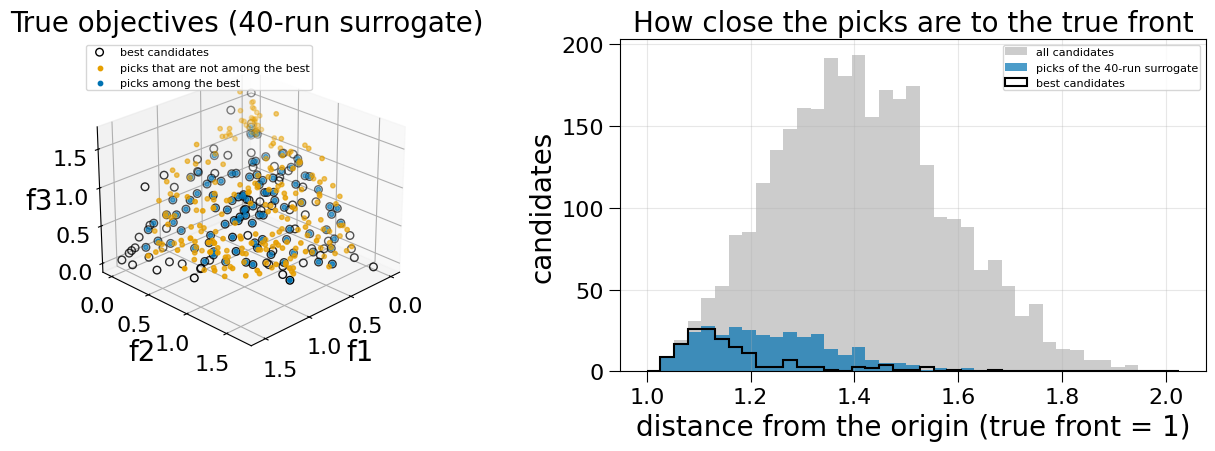

In [14]:
X = qmc.LatinHypercube(d, seed=0).random(40)
picks40 = pareto_mask(GaussianProcessSurrogate().fit(X, dtlz2(X)).predict(X_cand3))

fig = plt.figure(figsize=(13, 4.8))
ax = fig.add_subplot(1, 2, 1, projection="3d")
ax.scatter(*Y_cand3[best3].T, s=30, facecolor="none", edgecolor="black", label="best candidates")
ax.scatter(*Y_cand3[picks40 & ~best3].T, s=10, color=ORANGE, label="picks that are not among the best")
ax.scatter(*Y_cand3[picks40 & best3].T, s=10, color=BLUE, label="picks among the best")
ax.set(xlabel="f1", ylabel="f2", zlabel="f3", title="True objectives (40-run surrogate)")
ax.view_init(elev=25, azim=45)
ax.legend(fontsize=8, loc="upper left")

# Every DTLZ2 point lies at distance 1 + g from the origin; the true front is distance 1.
ax = fig.add_subplot(1, 2, 2)
dist = np.linalg.norm(Y_cand3, axis=1)
bins = np.linspace(1, dist.max(), 40)
ax.hist(dist, bins=bins, color="0.8", label="all candidates")
ax.hist(dist[picks40], bins=bins, color=BLUE, alpha=0.7, label="picks of the 40-run surrogate")
ax.hist(dist[best3], bins=bins, histtype="step", color="black", lw=1.5, label="best candidates")
ax.set(xlabel="distance from the origin (true front = 1)", ylabel="candidates",
       title="How close the picks are to the true front")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

**Reading the result.** DTLZ2 is harder to rank than ZDT1: with 20 runs only a fifth of the
best candidates are among the picks, and decision regret falls steadily as the training set
grows. Front fidelity is zero at every size, because the GP's predicted front is optimistic
throughout (the optimism check is positive); on its own it would suggest the 20-run surrogate
is as good as the 160-run one. All of these are exact three-dimensional hypervolumes.

<a id="summary"></a>
## 8. Summary

| Question | Call | Notes |
|---|---|---|
| Which points are Pareto-optimal? | `pareto_mask(Y, minimize=...)` | Pairwise comparison, so memory grows as $n^2$ |
| How much does a front dominate? | `hypervolume(Y, reference_point=ref)` | Exact for any number of objectives |
| How far is the predicted front from the true front? | `hypervolume_regret(Y_true, Y_pred, reference_point=ref)` | Clipped at 0: an optimistic model scores 0 |
| Is the surrogate optimistic? | `hypervolume_regret(Y_pred, Y_true, reference_point=ref)` | Positive when the predicted front dominates the true one |
| How much do the surrogate's picks cost? | `hypervolume_regret(Y_true, Y_true[pareto_mask(Y_pred)], reference_point=ref)` | Decision regret; 0 when the picks contain the best designs |
| Maximized objectives? | `minimize=[True, False, ...]` | Reference point: the worst point in your own units, with its maximized coordinates negated |
| Comparing models? | Fix `reference_point` | The default depends on `Y_pred` |
| Many objectives, large fronts? | Install `pymoo` (`[moo]` extra) | Same values, faster algorithm |
| Tracking a loop? | `RegretTracker(reference_point=ref).step(Y_true, Y_pred)` | Records front fidelity, scalarized regret and ε-indicator |

See the [multi-output surrogates tutorial](../docs/tutorials/multi_output_surrogates.ipynb)
for decision regret inside a full model-selection workflow.

**References**

- Zitzler, E., & Thiele, L. (1999). Multiobjective evolutionary algorithms: a comparative case
  study and the strength Pareto approach. *IEEE Transactions on Evolutionary Computation*, 3(4).
- While, L., Hingston, P., Barone, L., & Huband, S. (2006). A faster algorithm for calculating
  hypervolume. *IEEE Transactions on Evolutionary Computation*, 10(1).
- Deb, K., Thiele, L., Laumanns, M., & Zitzler, E. (2005). Scalable test problems for
  evolutionary multiobjective optimization. In *Evolutionary Multiobjective Optimization*,
  Springer.